# 🚀 High-Speed Wind Tunnel & Shock Tube Calculator
### Supersonic Blow-Down Wind Tunnel & Hypersonic Shock Tube

This notebook runs the complete **Wind Tunnel Technique** calculator in Google Colab.
It supports:
1. **Interactive In-Notebook GUI (via ipywidgets)** — No tunnels needed, works natively in Colab.
2. **Streamlit Cloudflare / LocalTunnel Web App** — Launch the full web dashboard from Colab.
3. **Automated Benchmark Runs (M = 2.0, 3.0, 5.0)** — Generate publication figures and CSV tables.

In [6]:
# 1. Clone your repository
!git clone https://github.com/restin-arch/High-Speed-Wind-Tunnel-Calculator.git

# 2. Navigate into the repository directory
%cd High-Speed-Wind-Tunnel-Calculator

# 3. Add to Python path and test import
import sys, os
sys.path.insert(0, os.path.abspath('.'))

from core import calculate_supersonic_tunnel, calculate_shock_tube
print("✅ Core package loaded successfully!")


Cloning into 'High-Speed-Wind-Tunnel-Calculator'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 48 (delta 12), reused 45 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 1.14 MiB | 29.88 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/High-Speed-Wind-Tunnel-Calculator/High-Speed-Wind-Tunnel-Calculator
✅ Core package loaded successfully!


## 1. Environment Setup & Dependency Installation

In [7]:
# Install dependencies in Colab
!pip install -q numpy scipy matplotlib pandas streamlit
print("✅ Dependencies successfully installed!")

✅ Dependencies successfully installed!


## 2. Load or Download Project Code
If you uploaded the project files to Colab or Google Drive, make sure the `core/` folder is in your current directory.
Run the cell below to verify:

In [8]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))

# Check if core package is present
try:
    from core import calculate_supersonic_tunnel, calculate_shock_tube, generate_nozzle_contour
    print("✅ Core Aerodynamics package successfully loaded!")
except ImportError as e:
    print("⚠️ Core package not found in current directory. If running from GitHub, clone your repo:")
    print("!git clone <YOUR_REPO_URL> && cd <REPO_DIR>")

✅ Core Aerodynamics package successfully loaded!


## 3. Run Benchmark Cases (M = 2.0, 3.0, 5.0)

RUNNING BENCHMARK CASES FOR M = 2.0, 3.0, 5.0

---> Computing Supersonic Tunnel at Mach 2.0...
---> Generating Nozzle Contour for Mach 2.0...
---> Computing Shock Tube for Ms = 2.0...

---> Computing Supersonic Tunnel at Mach 3.0...
---> Generating Nozzle Contour for Mach 3.0...
---> Computing Shock Tube for Ms = 3.0...

---> Computing Supersonic Tunnel at Mach 5.0...
---> Generating Nozzle Contour for Mach 5.0...
---> Computing Shock Tube for Ms = 5.0...
Saved: /content/High-Speed-Wind-Tunnel-Calculator/High-Speed-Wind-Tunnel-Calculator/outputs/plots/mach_vs_nozzle_position.png
Saved: /content/High-Speed-Wind-Tunnel-Calculator/High-Speed-Wind-Tunnel-Calculator/outputs/plots/nozzle_contours_geometry.png
Saved: /content/High-Speed-Wind-Tunnel-Calculator/High-Speed-Wind-Tunnel-Calculator/outputs/plots/tank_pressure_vs_time.png
Saved: /content/High-Speed-Wind-Tunnel-Calculator/High-Speed-Wind-Tunnel-Calculator/outputs/plots/shock_tube_xt_diagram_m3.png
Saved: /content/High-Speed-Wind-Tunn

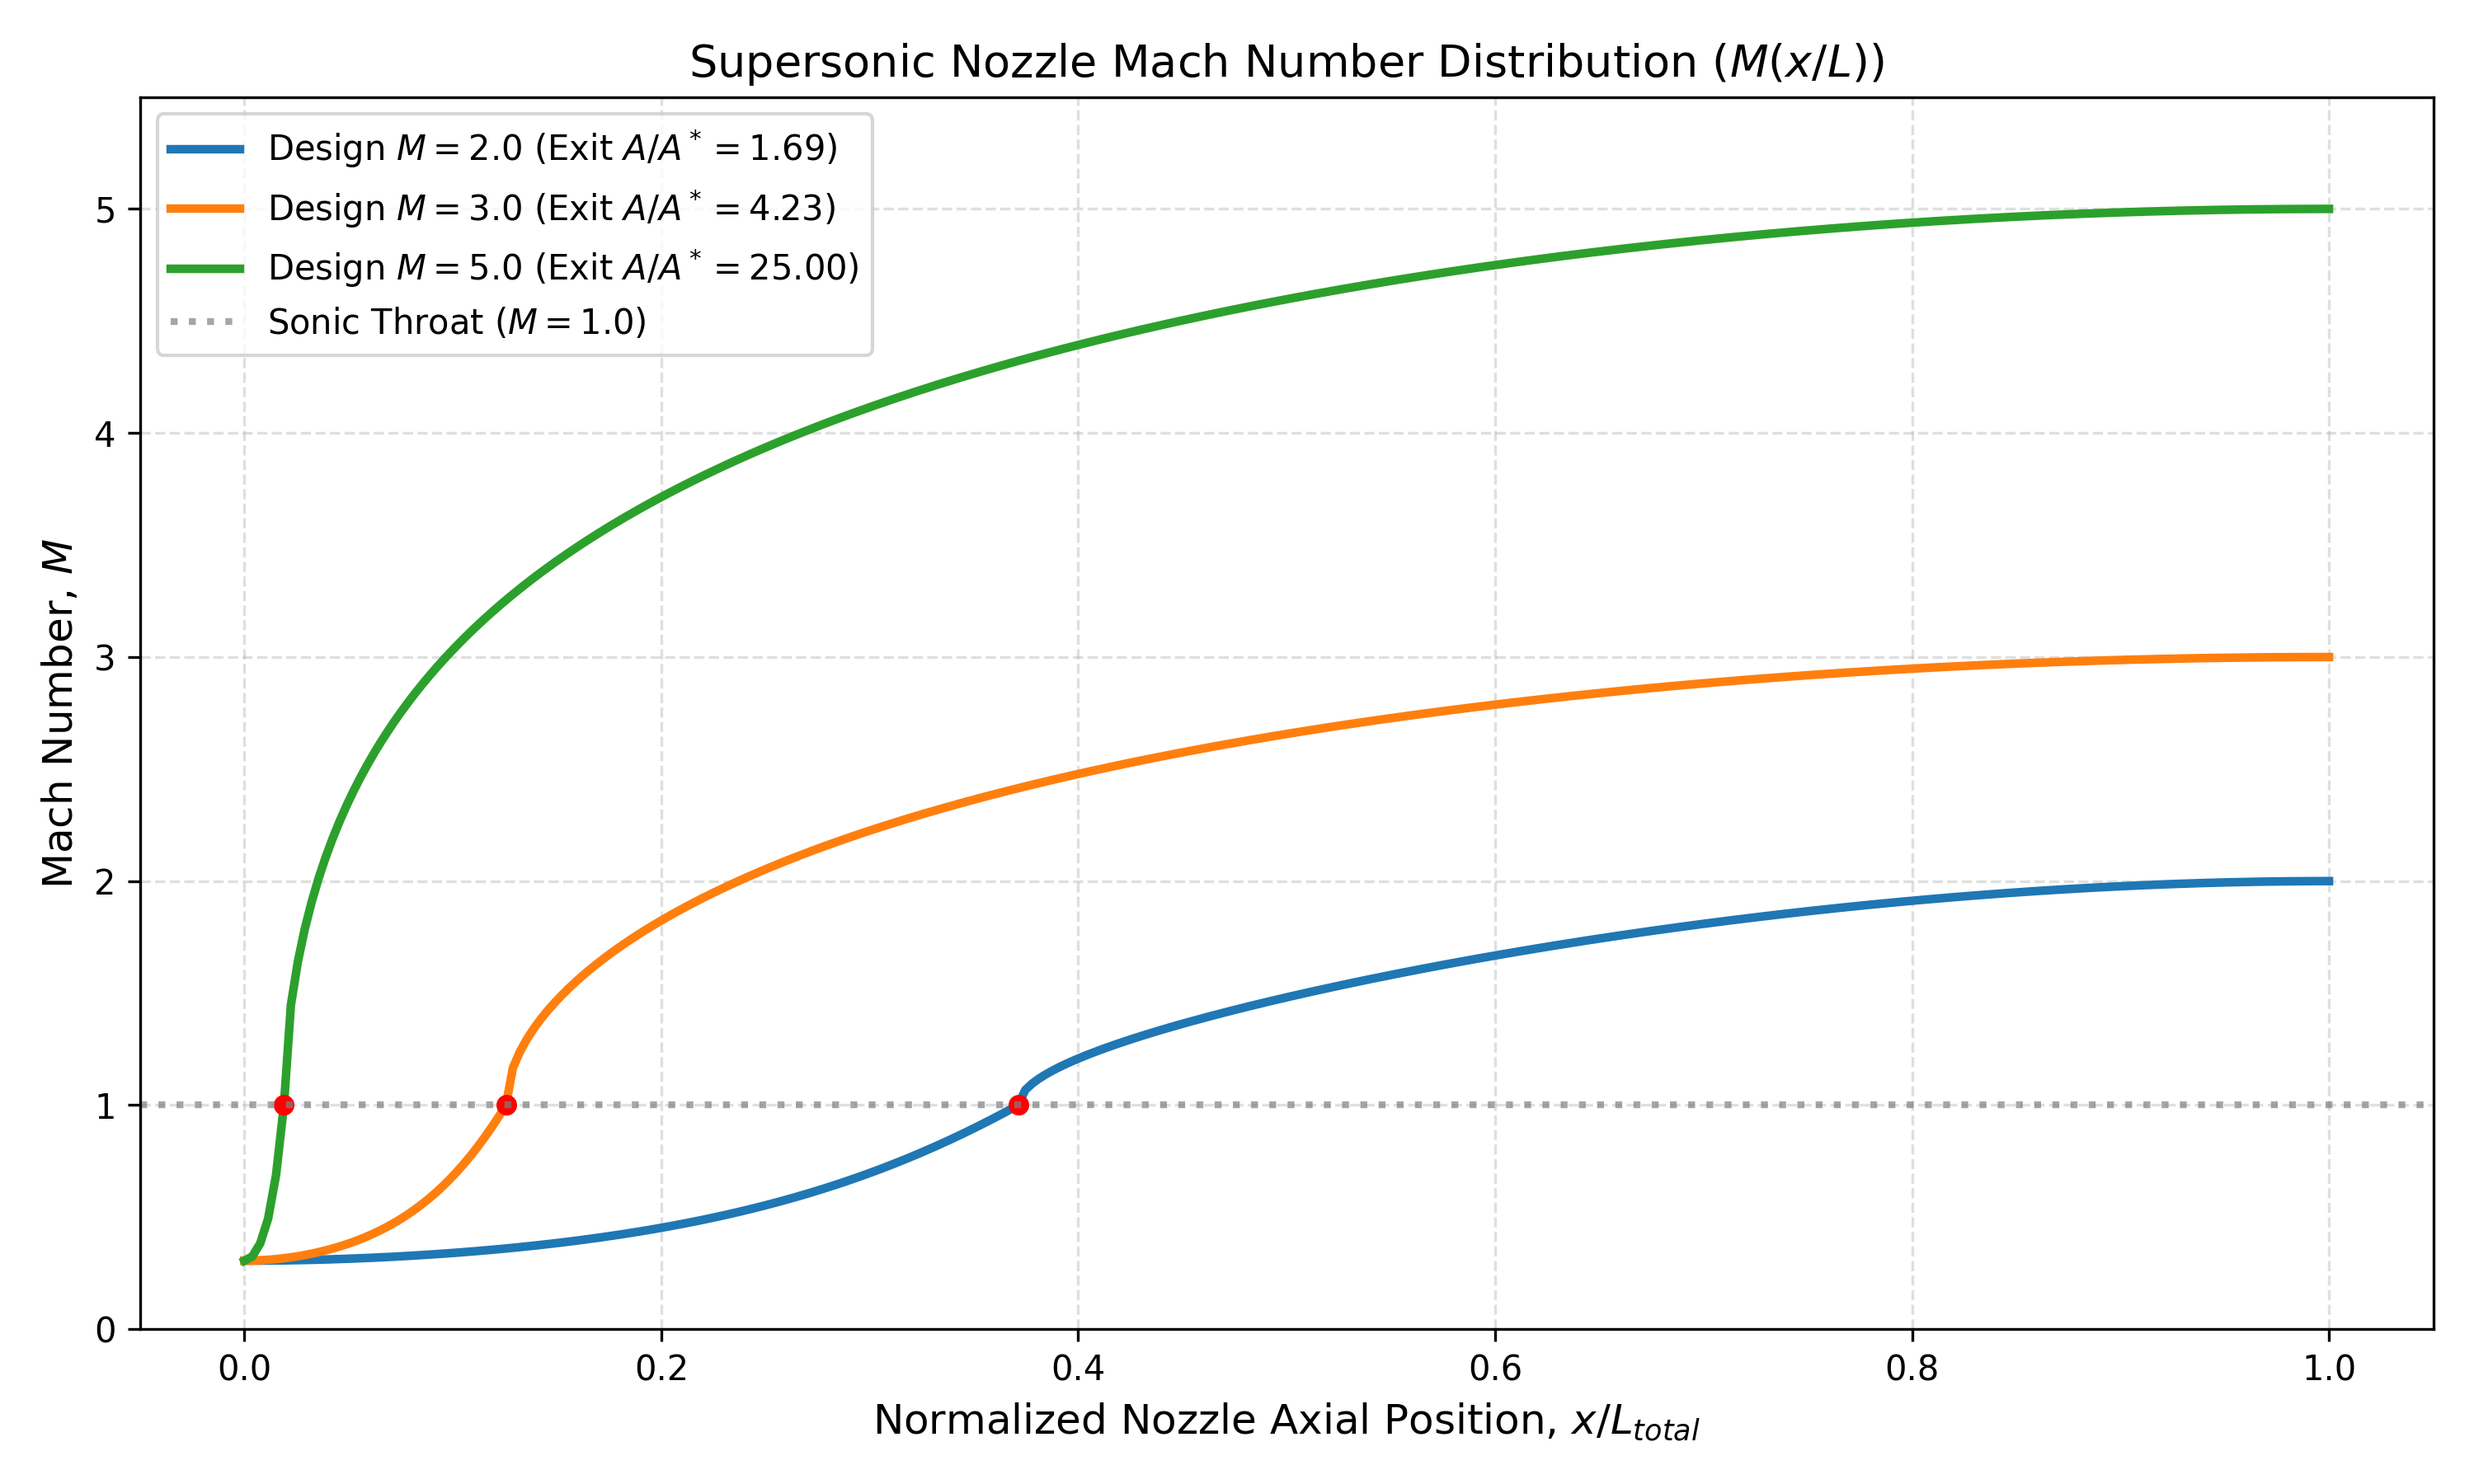


--- 2. Storage Tank Pressure Decay vs Time ---


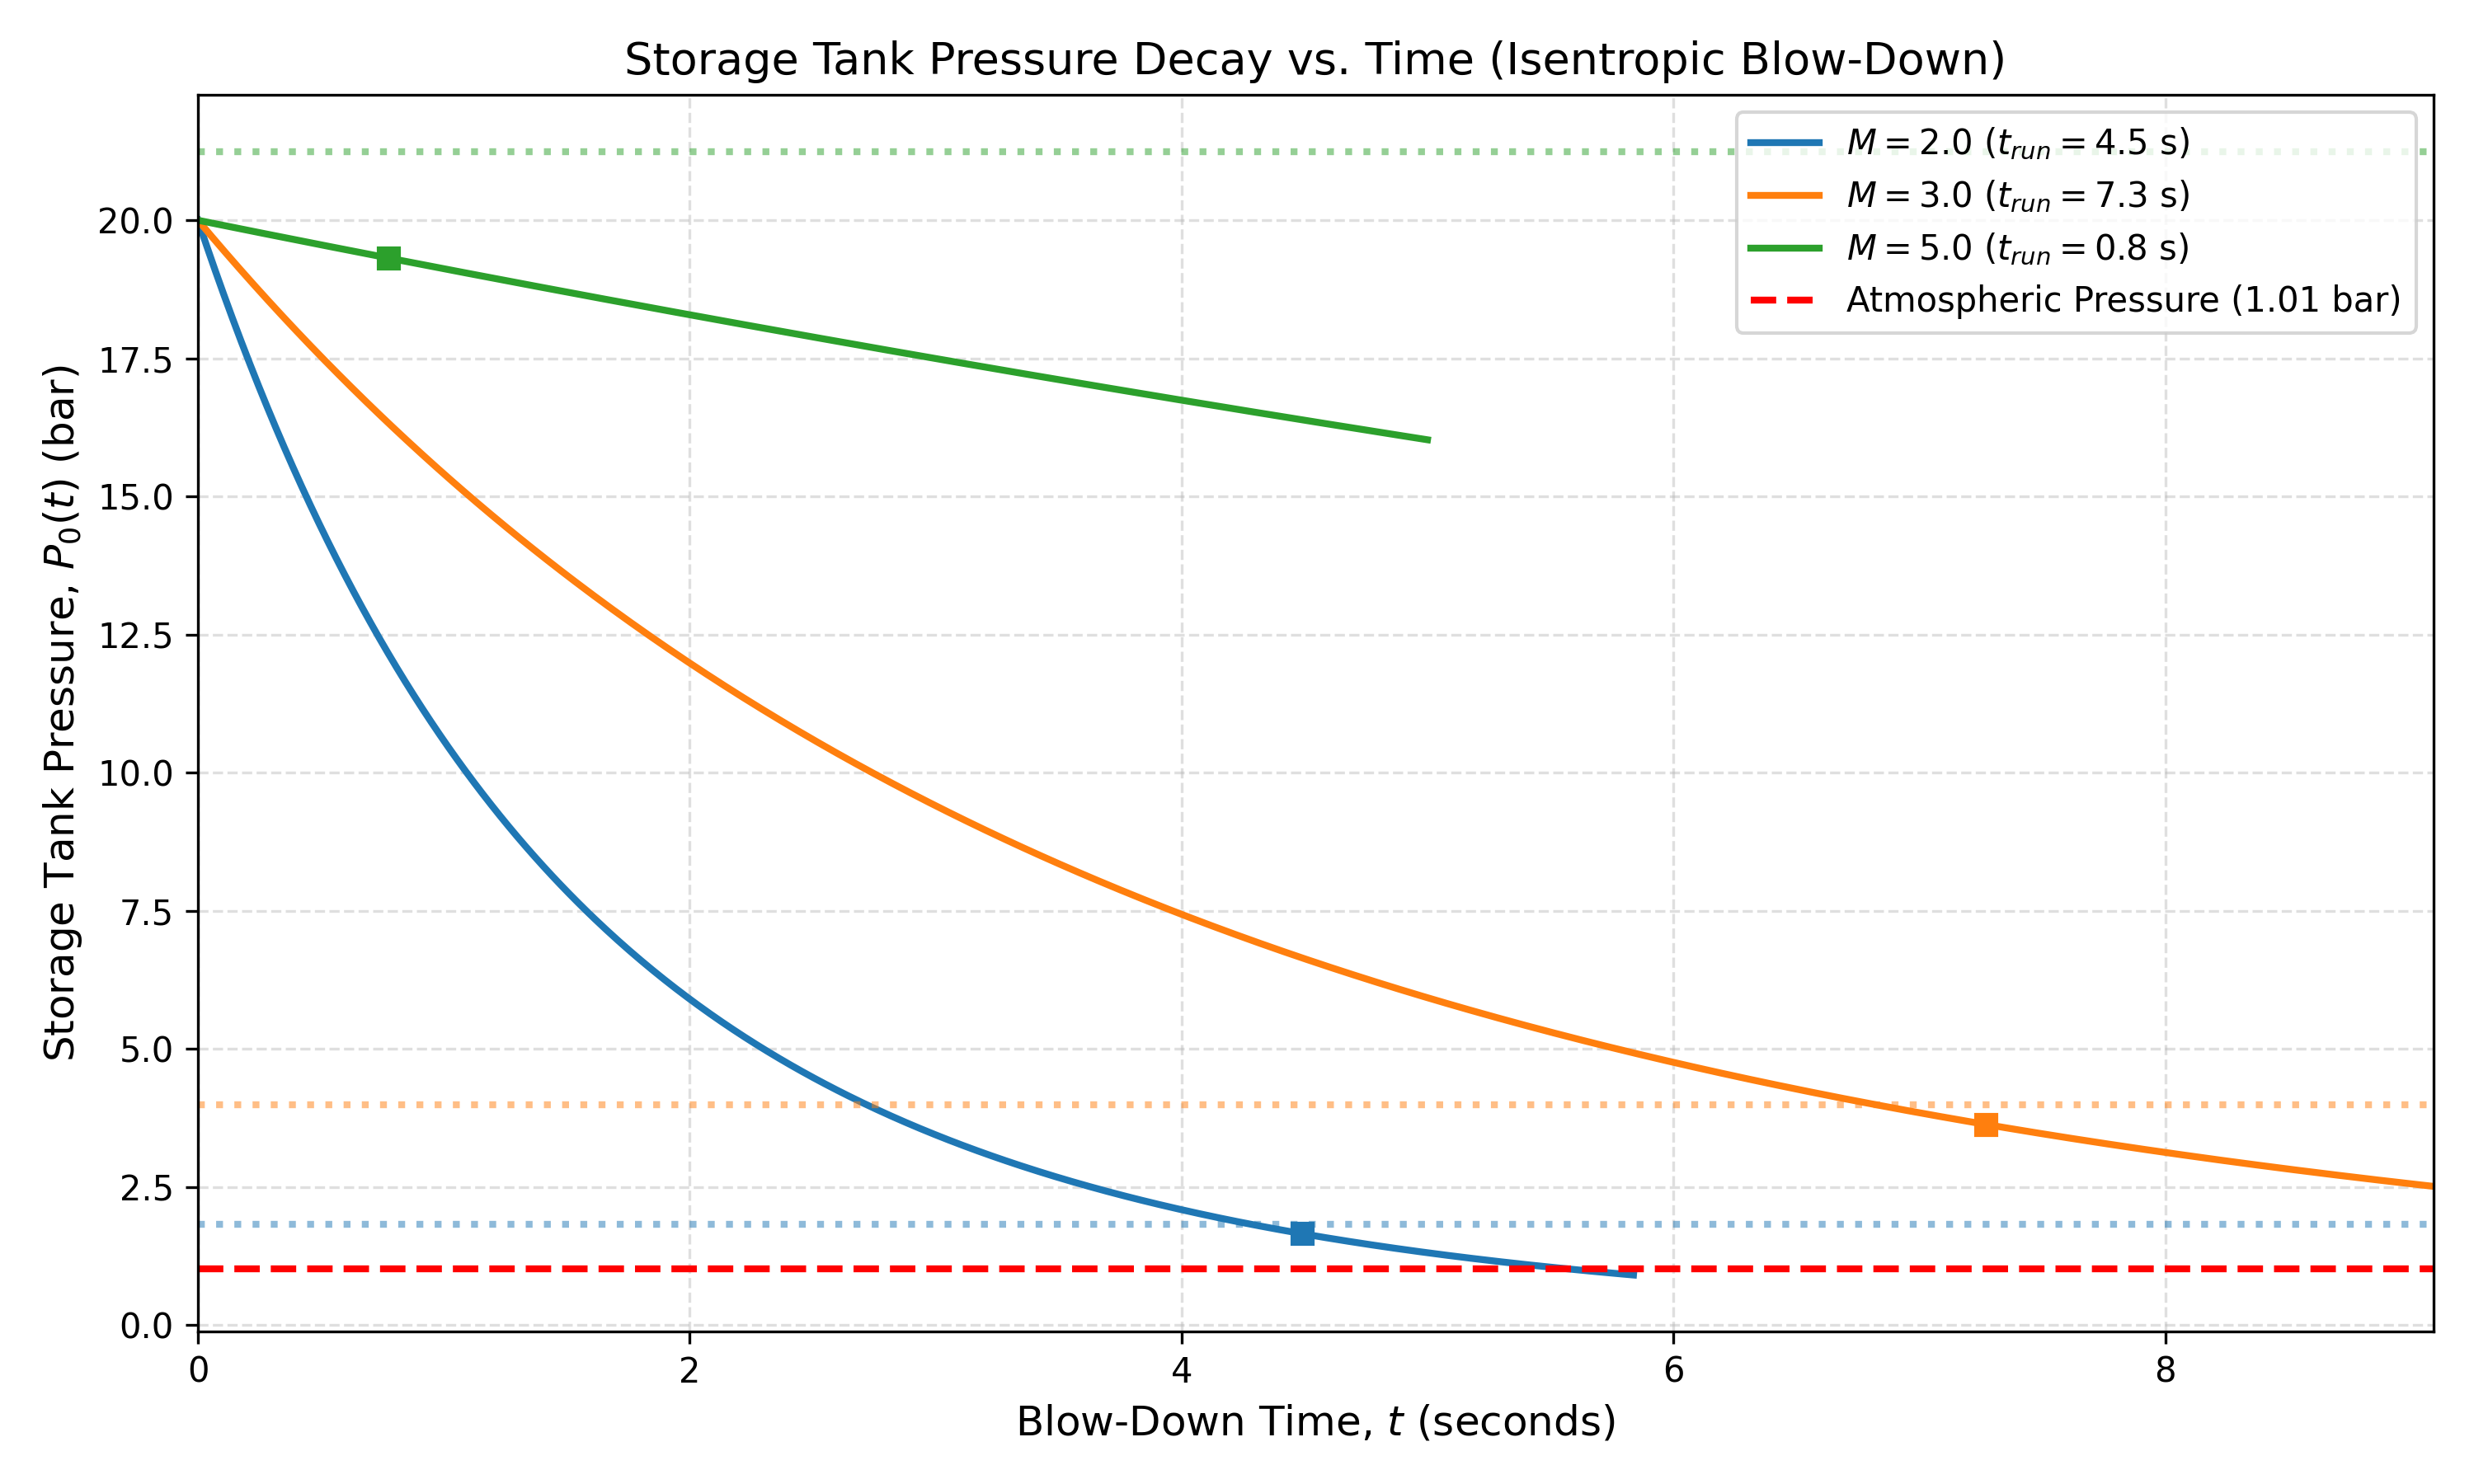


--- 3. Shock Tube x-t Wave Diagram (Ms = 3.0) ---


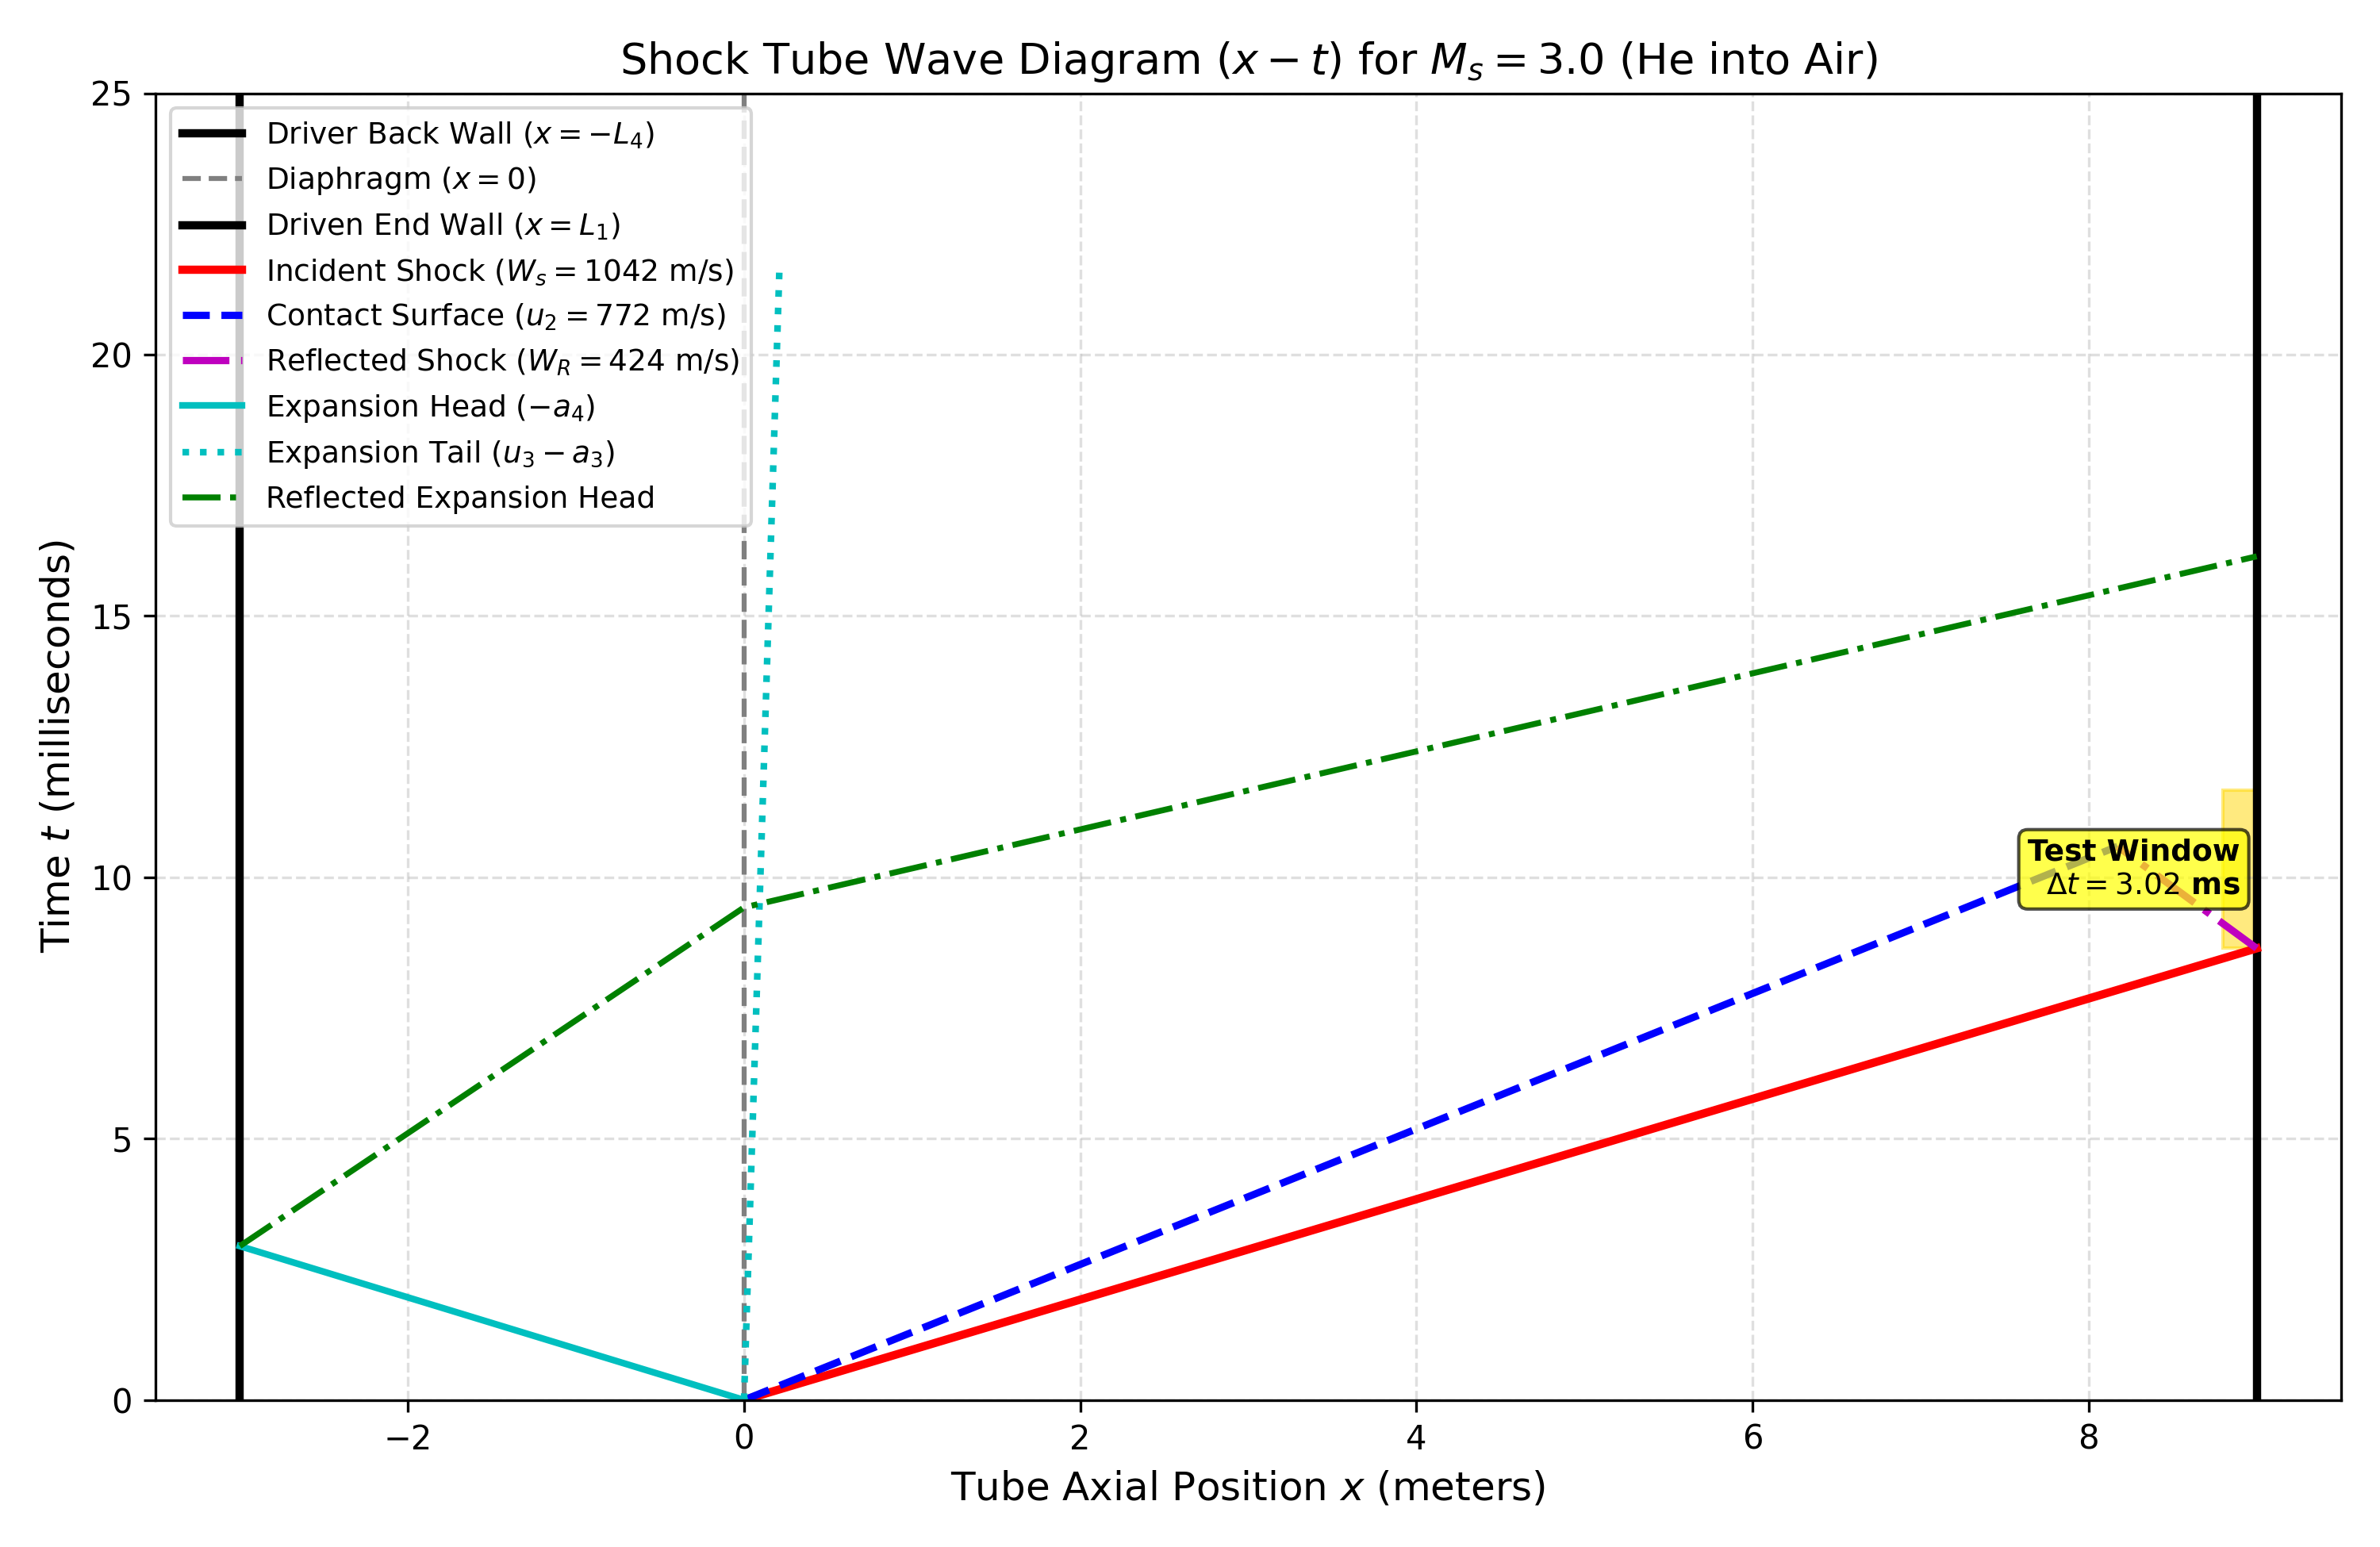

In [9]:
# Run Day 4 benchmarks and display plots inline
!python generate_sample_runs.py

from IPython.display import Image, display
print("\n--- 1. Mach Number vs Nozzle Position ---")
display(Image("outputs/plots/mach_vs_nozzle_position.png"))

print("\n--- 2. Storage Tank Pressure Decay vs Time ---")
display(Image("outputs/plots/tank_pressure_vs_time.png"))

print("\n--- 3. Shock Tube x-t Wave Diagram (Ms = 3.0) ---")
display(Image("outputs/plots/shock_tube_xt_diagram_m3.png"))

## 4. Interactive In-Notebook GUI (ipywidgets)
Use interactive sliders and dropdowns right inside Google Colab without needing any external tunnels!

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np
from core import calculate_supersonic_tunnel, generate_nozzle_contour, calculate_shock_tube

# Tab 1: Supersonic Wind Tunnel Controls
m_slider = widgets.FloatSlider(value=2.5, min=1.2, max=5.0, step=0.1, description='Mach (M):')
p0_slider = widgets.FloatSlider(value=15.0, min=2.0, max=50.0, step=1.0, description='P₀ (bar):')
v_slider = widgets.FloatSlider(value=10.0, min=1.0, max=50.0, step=1.0, description='Vol (m³):')
a_slider = widgets.FloatSlider(value=0.04, min=0.01, max=0.2, step=0.01, description='Area (m²):')

out_ss = widgets.Output()

def update_supersonic(change=None):
    with out_ss:
        clear_output(wait=True)
        M = m_slider.value
        P0 = p0_slider.value * 1e5
        V = v_slider.value
        A = a_slider.value

        res = calculate_supersonic_tunnel(mach=M, test_area=A, tank_pressure_init=P0, tank_volume=V)
        noz = generate_nozzle_contour(mach_design=M, test_area=A)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=100)

        # Mach profile
        ax1.plot(noz.x_normalized, noz.mach_distribution, 'b-', lw=2.2, label='M(x/L)')
        ax1.axhline(1.0, color='gray', linestyle=':', label='Throat (M=1.0)')
        ax1.set_xlabel('x / L_total')
        ax1.set_ylabel('Mach Number M')
        ax1.set_title(f'Nozzle Mach Profile (Exit M={M:.1f}, A/A*={res.area_ratio:.2f})')
        ax1.grid(True, alpha=0.3)
        ax1.legend()

        # Tank decay
        ax2.plot(res.time_array, res.p0_time_adiabatic / 1e5, 'r-', lw=2.2, label='P0(t) Adiabatic')
        ax2.axhline(res.p0_starting / 1e5, color='orange', linestyle='--', label=f'Starting P0={res.p0_starting/1e5:.1f} bar')
        ax2.axhline(res.p0_min_running / 1e5, color='purple', linestyle=':', label=f'Running P0={res.p0_min_running/1e5:.1f} bar')
        ax2.set_xlabel('Time (s)')
        ax2.set_ylabel('Tank Pressure (bar)')
        ax2.set_title(f'Tank Blow-Down (Adiabatic Runtime = {res.runtime_adiabatic_to_run:.2f} s)')
        ax2.grid(True, alpha=0.3)
        ax2.legend()

        plt.tight_layout()
        plt.show()

        print(f"Throat Area A*: {res.throat_area*1e4:.2f} cm² | Throat Diam: {res.throat_diameter_equiv*100:.2f} cm | Mass Flow: {res.mass_flow_rate_init:.2f} kg/s")
        print(f"Test Static Temp: {res.static_temp:.1f} K | Static Press: {res.static_pressure/1e3:.2f} kPa | Velocity: {res.flow_velocity:.1f} m/s")

for w in [m_slider, p0_slider, v_slider, a_slider]:
    w.observe(update_supersonic, names='value')

display(widgets.VBox([widgets.HBox([m_slider, p0_slider]), widgets.HBox([v_slider, a_slider]), out_ss]))
update_supersonic()

## 5. Option B: Run the Streamlit Web Application in Colab
You can also run the full multi-tab Streamlit dashboard with a secure tunnel:

In [ ]:
# Download cloudflared for secure tunnel in Colab
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

# Launch Streamlit in background
import subprocess
subprocess.Popen(["streamlit", "run", "app_streamlit.py", "--server.port", "8501", "--server.headless", "true"])

# Launch Cloudflare tunnel to get public URL
print("Tunnel is starting... Click the public https link below:")
!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

Tunnel is starting... Click the public https link below:
2026-10-29T05:30:18Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-29T05:30:18Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-29T05:30:21Z INF +--------------------------------------------------------------------------------------------+
2026-10-29T05:30:21Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-29T05:30:21Z INF